# Comprobación final del modelo seleccionado

Este notebook corresponde al punto V, apartado 5.1. Evalúa el árbol de decisión y su preprocesamiento ya guardados en el notebook 02 sobre las **2 000 observaciones reservadas para prueba**.

No se entrenan modelos, no se comparan nuevas configuraciones y no se ajustan umbrales. Los resultados siguientes ya no deben utilizarse para volver a seleccionar el modelo sobre esta misma reserva. La simulación de la interfaz sigue pendiente.

Ejecutar después de los notebooks 01 y 02, utilizando el entorno del proyecto y el mismo artefacto registrado en `model_selection.json`.

In [1]:
from pathlib import Path
import sys, json, platform
from importlib.metadata import version
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/evaluation.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Abrir el notebook dentro del repositorio con src/ y data/.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display
from src.preparation import TARGET, FEATURES
from src.evaluation import load_frozen_experiment, evaluate_frozen_model, classification_metrics, file_sha256
REPORTS = ROOT / 'reports'
OUTPUTS = ROOT / 'outputs'
OUTPUTS.mkdir(parents=True, exist_ok=True)
model, test, selection, fingerprints = load_frozen_experiment(ROOT)
print('Modelo congelado:', selection['selected_model'])
print('Observaciones de prueba:', len(test))
print('Fallas reales:', int(test[TARGET].sum()))
display(pd.Series(selection['selected_params'], name='Parámetros ya seleccionados'))
print('Versiones, huella del modelo, composición de prueba y ausencia de cruce de identificadores verificadas.')

Modelo congelado: Árbol de decisión
Observaciones de prueba: 2000
Fallas reales: 68


model__class_weight        NaN
model__max_depth           NaN
model__min_samples_leaf    5.0
Name: Parámetros ya seleccionados, dtype: float64

Versiones, huella del modelo, composición de prueba y ausencia de cruce de identificadores verificadas.


## Predicciones del pipeline guardado

Se utilizan solo las seis variables de entrada. La etiqueta principal se conserva aparte para evaluar los aciertos y errores. Los indicadores de tipos de falla y los identificadores no se entregan al modelo.

La integridad de las observaciones de prueba se comprueba contra el CSV original. Esa comparación no se utiliza para ajustar el pipeline. Las salidas numéricas del árbol se registran como scores sin calibrar, no como probabilidades calibradas ni garantías de falla.

In [2]:
predictions, metrics, latency = evaluate_frozen_model(model, test)
# Una referencia mayoritaria ayuda a interpretar la exactitud en datos desbalanceados.
baseline_metrics = classification_metrics(test[TARGET], np.zeros(len(test), dtype=int))
assert metrics['rows'] == 2000
assert metrics['true_positive'] + metrics['false_negative'] == int(test[TARGET].sum())
assert metrics['true_negative'] + metrics['false_positive'] == int((test[TARGET] == 0).sum())
assert sum(metrics[name] for name in ['true_negative', 'false_positive', 'false_negative', 'true_positive']) == len(test)
assert len(predictions) == len(test)
comparison = pd.DataFrame([
    {'modelo': selection['selected_model'], **{key: metrics[key] for key in
        ['accuracy', 'precision', 'recall', 'f1', 'false_positive_rate', 'false_negative_rate']}},
    {'modelo': 'Siempre sin falla', **{key: baseline_metrics[key] for key in
        ['accuracy', 'precision', 'recall', 'f1', 'false_positive_rate', 'false_negative_rate']}},
]).set_index('modelo')
display(comparison)
counts = pd.Series({
    'Sin falla correctamente reconocida (TN)': metrics['true_negative'],
    'Falsas alarmas (FP)': metrics['false_positive'],
    'Fallas omitidas (FN)': metrics['false_negative'],
    'Fallas detectadas (TP)': metrics['true_positive'],
}, name='observaciones')
display(counts)

,accuracy,precision,recall,f1,false_positive_rate,false_negative_rate
modelo,,,,,,
Árbol de decisión,0.9845,0.793651,0.735294,0.763359,0.006729,0.264706
Siempre sin falla,0.9660,0.000000,0.000000,0.000000,0.000000,1.000000


Sin falla correctamente reconocida (TN)    1919
Falsas alarmas (FP)                          13
Fallas omitidas (FN)                         18
Fallas detectadas (TP)                       50
Name: observaciones, dtype: int64

## Matriz de confusión en prueba

Las filas representan la etiqueta real y las columnas la predicción. La falla es la clase positiva. Una falsa alarma (FP) es una observación sin falla clasificada como con falla; una omisión (FN) es una falla clasificada como sin falla.

La exactitud utiliza los 2 000 casos. La sensibilidad se calcula solo sobre las fallas reales, mientras que la tasa de falsas alarmas utiliza las observaciones realmente sin falla. Estos denominadores son diferentes.

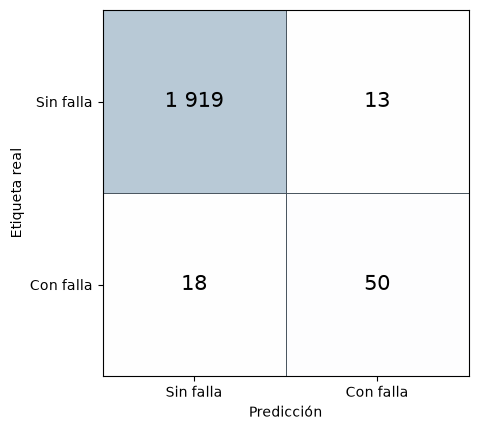

In [3]:
matrix = np.array([[metrics['true_negative'], metrics['false_positive']],
                   [metrics['false_negative'], metrics['true_positive']]])
fig, ax = plt.subplots(figsize=(5.5, 4.4))
colors = LinearSegmentedColormap.from_list('light_blue', ['#FFFFFF', '#B8C9D6'])
ax.imshow(matrix, cmap=colors, vmin=0, vmax=matrix.max())
ax.set_xticks([0, 1], ['Sin falla', 'Con falla'])
ax.set_yticks([0, 1], ['Sin falla', 'Con falla'])
ax.set_xlabel('Predicción')
ax.set_ylabel('Etiqueta real')
for (row, col), count in np.ndenumerate(matrix):
    ax.text(col, row, f'{count:,}'.replace(',', ' '), ha='center', va='center', color='black', fontsize=15)
ax.set_xticks(np.arange(-.5, 2, 1), minor=True)
ax.set_yticks(np.arange(-.5, 2, 1), minor=True)
ax.grid(which='minor', color='#46525C', linewidth=.7)
ax.tick_params(which='minor', bottom=False, left=False)
fig.tight_layout()
fig.savefig(OUTPUTS / 'matriz_confusion_prueba.png', dpi=220, bbox_inches='tight', facecolor='white')
plt.show()

## Tiempos locales de predicción

Se realizan tres llamadas de calentamiento, excluidas del cronometraje, y luego una llamada `predict` por observación. El tiempo incluye el preprocesamiento y la clasificación del pipeline. No incluye cargar el CSV, seleccionar la fila, ejecutar la interfaz, calcular scores ni las pausas de una simulación.

Repetir una inferencia para medir tiempos no vuelve a entrenar el modelo. Se comprueba que las predicciones individuales coincidan con las obtenidas por lote. El promedio y el percentil 95 describen esta ejecución local; no certifican respuesta en tiempo real industrial.

In [4]:
display(pd.Series(latency, name='medición local'))
assert latency['observations'] == len(test)
assert latency['mean_ms'] > 0 and latency['p95_ms'] > 0
print('Equipo de ejecución:', platform.system(), platform.machine())
print('Python:', platform.python_version())

observations                                                          2000
mean_ms                                                           2.590741
median_ms                                                           2.3687
p95_ms                                                            4.349815
definition               Una llamada predict por observación: incluye t...
warmup_calls_excluded                                                    3
Name: medición local, dtype: object

Equipo de ejecución: Windows AMD64
Python: 3.12.14


## Exportación y trazabilidad

El archivo de selección del notebook 02 se conserva como evidencia histórica anterior a prueba; su campo `test_evaluated` permanece en falso. Este notebook genera un reporte separado que registra la evaluación final realizada y la huella exacta del modelo usado. No se sobrescribe el modelo ni sus parámetros.

Las predicciones exportadas incluyen las entradas, la etiqueta real, la predicción, el score sin calibrar, el tiempo local y el tipo de resultado (TN/FP/FN/TP). Son datos sintéticos del proyecto. El Word no se modifica desde este notebook.

In [5]:
assert file_sha256(ROOT / selection['model_artifact']) == fingerprints['model_sha256']
assert file_sha256(REPORTS / 'model_selection.json') == fingerprints['selection_sha256']
assert file_sha256(ROOT / 'data/processed/test.csv') == fingerprints['test_csv_sha256']
report = {
    'selected_model': selection['selected_model'],
    'selected_params': selection['selected_params'],
    'test_evaluated': True,
    'test_rows': len(test), 'test_failure_count': int(test[TARGET].sum()),
    'test_id_sha256': __import__('hashlib').sha256(','.join(map(str, test['UDI'])).encode('ascii')).hexdigest(),
    'model_selection_sha256': fingerprints['selection_sha256'],
    'model_sha256': fingerprints['model_sha256'],
    'test_csv_sha256': fingerprints['test_csv_sha256'],
    'features': FEATURES, 'positive_class': 1,
    'metrics': metrics, 'majority_baseline': baseline_metrics,
    'latency': latency,
    'environment': {'system': platform.system(), 'architecture': platform.machine(),
                    'python': platform.python_version(),
                    'versions': {package: version(package) for package in selection['versions']}},
    'method': 'Evaluación del pipeline ya fijado; sin entrenamiento, búsqueda ni ajuste de umbral con prueba.',
    'limitations': ['Datos sintéticos y partición aleatoria del mismo dataset.',
                    'Evaluación respecto de Machine failure; discrepancias de etiquetas conservadas.',
                    'La simulación de interfaz y la validación en maquinaria física no se han realizado.'],
}
(REPORTS / 'test_evaluation.json').write_text(json.dumps(report, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
predictions.to_csv(REPORTS / 'test_predictions.csv', index=False)
comparison.to_csv(REPORTS / 'test_model_comparison.csv')
print('Reporte y predicciones exportados. Modelo, parámetros y reserva original intactos.')
print(f"Se detectaron {metrics['true_positive']} de {metrics['true_positive'] + metrics['false_negative']} fallas; "
      f"se omitieron {metrics['false_negative']} y se generaron {metrics['false_positive']} falsas alarmas.")

Reporte y predicciones exportados. Modelo, parámetros y reserva original intactos.
Se detectaron 50 de 68 fallas; se omitieron 18 y se generaron 13 falsas alarmas.


## Interpretación

Los resultados de este notebook corresponden a una reserva que no intervino en el entrenamiento o la selección del pipeline. No deben confundirse con los promedios de validación del notebook 02. Se reportan tanto aciertos como fallas omitidas y falsas alarmas, evitando presentar la exactitud como única evidencia.

La reserva contiene pocas fallas respecto al total, por lo que los conteos son importantes para interpretar los porcentajes. La capacidad observada se limita al conjunto sintético y a su etiqueta principal. Cualquier cambio de configuración motivado por estos resultados requerirá otra evaluación independiente; esta reserva ya fue consultada.

La siguiente etapa es construir la simulación con el pipeline fijado, sin usar su interfaz para reajustarlo con prueba.

## Fuentes de las métricas

- [Matriz de confusión](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html).
- [Precisión, sensibilidad y F1](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_fscore_support.html).
- [Dataset AI4I 2020](https://doi.org/10.24432/C5HS5C).